# Machine Learning Zoomcamp 2026 — Homework 4

Classification evaluation using the pinned 2026 lead-scoring dataset. Corrected from the original notebook, with all six questions. Run the notebook with the supplied CSV in the same folder (or adjust the path).

## Data preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

# Keep the dataset alongside this notebook.
df = pd.read_csv('course_lead_scoring_2026.csv')
print('Shape:', df.shape)
print('Missing values before filling:')
print(df.isna().sum())

Shape: (5000, 9)
Missing values before filling:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [2]:
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
numerical_columns = [c for c in df.select_dtypes(include=['number']).columns if c != 'converted']

df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0.0)
assert df.isna().sum().sum() == 0

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
print('Train/validation/test:', len(df_train), len(df_val), len(df_test))

Train/validation/test: 3000 1000 1000


## Question 1 — Numerical feature ROC AUC

In [3]:
auc_scores = {}
for feature in numerical_columns:
    auc = roc_auc_score(df_train['converted'], df_train[feature])
    auc_scores[feature] = max(auc, 1 - auc)
print(pd.Series(auc_scores).sort_values(ascending=False))
print('Q1 answer:', max(auc_scores, key=auc_scores.get))

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64
Q1 answer: lead_score


## Question 2 — Logistic regression validation ROC AUC

In [4]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values

train_dicts = df_train.drop(columns=['converted']).to_dict(orient='records')
val_dicts = df_val.drop(columns=['converted']).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred)
print(f'Q2 answer: {auc_val:.3f}')

Q2 answer: 0.732


## Question 3 — Precision / recall intersection

Q3 answer: 0.63
Precision: 0.7328; recall: 0.7253


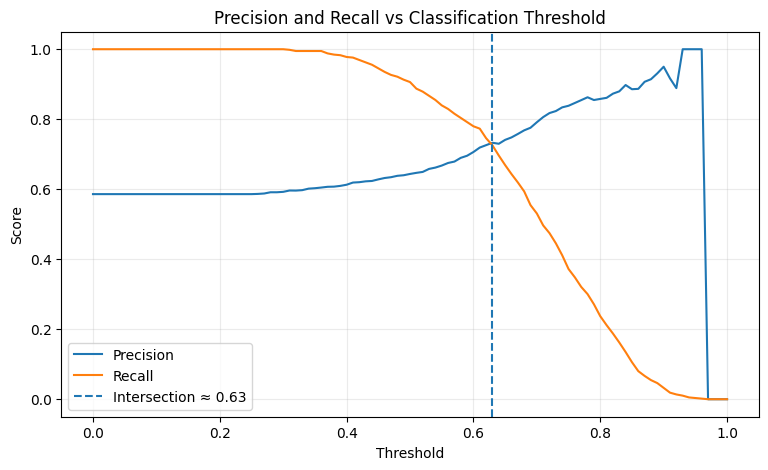

In [5]:
thresholds = np.arange(0, 1.01, 0.01)
precisions = np.array([precision_score(y_val, y_pred >= t, zero_division=0) for t in thresholds])
recalls = np.array([recall_score(y_val, y_pred >= t, zero_division=0) for t in thresholds])

differences = np.abs(precisions - recalls)
differences[(precisions == 0) & (recalls == 0)] = np.inf
intersection_idx = int(np.argmin(differences))
print(f'Q3 answer: {thresholds[intersection_idx]:.2f}')
print(f'Precision: {precisions[intersection_idx]:.4f}; recall: {recalls[intersection_idx]:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.axvline(thresholds[intersection_idx], linestyle='--', label=f'Intersection ≈ {thresholds[intersection_idx]:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Score')
plt.title('Precision and Recall vs Classification Threshold')
plt.grid(alpha=.25); plt.legend(); plt.show()

## Question 4 — Best F1 threshold

Q4 answer: 0.41; max F1 = 0.7576


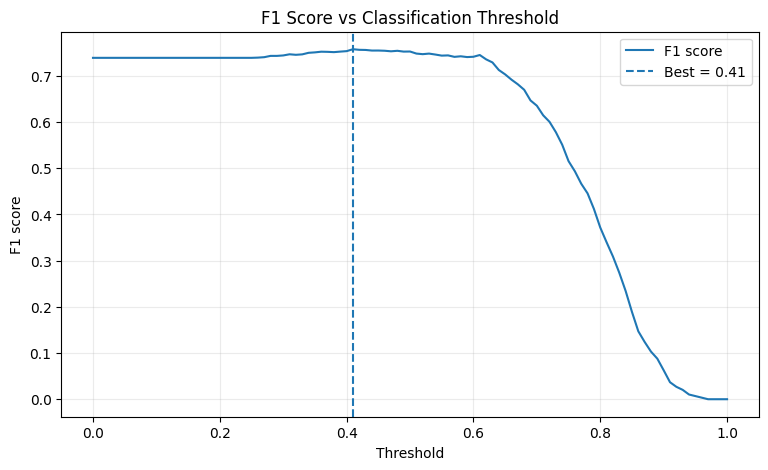

In [6]:
f1_scores = np.array([f1_score(y_val, y_pred >= t, zero_division=0) for t in thresholds])
f1_idx = int(np.argmax(f1_scores))
print(f'Q4 answer: {thresholds[f1_idx]:.2f}; max F1 = {f1_scores[f1_idx]:.4f}')
plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, label='F1 score')
plt.axvline(thresholds[f1_idx], linestyle='--', label=f'Best = {thresholds[f1_idx]:.2f}')
plt.xlabel('Threshold'); plt.ylabel('F1 score'); plt.title('F1 Score vs Classification Threshold')
plt.grid(alpha=.25); plt.legend(); plt.show()

## Questions 5 and 6 — 5-Fold cross-validation and C tuning

In [7]:
def fold_auc(df_fold_train, df_fold_val, C=1.0):
    fold_dv = DictVectorizer(sparse=False)
    X_fold_train = fold_dv.fit_transform(df_fold_train.drop(columns=['converted']).to_dict('records'))
    X_fold_val = fold_dv.transform(df_fold_val.drop(columns=['converted']).to_dict('records'))
    fold_model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    fold_model.fit(X_fold_train, df_fold_train['converted'])
    y_fold_pred = fold_model.predict_proba(X_fold_val)[:, 1]
    return roc_auc_score(df_fold_val['converted'], y_fold_pred)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
cv_results = []
for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]
        scores.append(fold_auc(df_fold_train, df_fold_val, C=C))
    cv_results.append({'C': C, 'mean_auc': np.mean(scores), 'std_auc': np.std(scores), 'fold_aucs': scores})

for row in cv_results:
    print(f"C={row['C']:.6g}: mean={row['mean_auc']:.3f}, std={row['std_auc']:.3f}; folds={np.round(row['fold_aucs'], 4)}")
q5 = next(row for row in cv_results if row['C'] == 1)
print(f"Q5 answer: {q5['std_auc']:.3f}")
# Compare rounded values, as requested by the assignment, before applying tie-break rules.
q6 = sorted(cv_results, key=lambda row: (-round(row['mean_auc'], 3), round(row['std_auc'], 3), row['C']))[0]
print(f"Q6 answer: {q6['C']:.6g}")

C=1e-06: mean=0.617, std=0.019; folds=[0.5941 0.6402 0.6002 0.6364 0.6128]
C=0.001: mean=0.749, std=0.010; folds=[0.7504 0.7475 0.7584 0.7584 0.7311]
C=1: mean=0.732, std=0.007; folds=[0.7306 0.7296 0.7363 0.7412 0.7209]
Q5 answer: 0.007
Q6 answer: 0.001


## Answer summary

1. **lead_score**
2. **0.732**
3. **0.63**
4. **0.41**
5. **0.007**
6. **0.001**

No test-set predictions are used in model selection. The categorical encoder is fit separately inside each cross-validation training fold.